# 부록 A. 학습형 비교 모델 (이전 04) — SKT 정답으로 학습한 위험도와 실시간 규칙 T


| 단계 | 노트북 | 질문 |
|---|---|---|
| 00 | 프로젝트 개요 | 무엇을, 왜, 어떤 순서로 하는가 |
| 01 | 데이터 준비 · 품질 점검 | 받은 데이터를 그대로 믿고 써도 되는가 |
| 02 | 탐색 분석 — 고립 신호 | 데이터에서 연령·성별·지역별 고립 신호 후보가 보이는가 |
| 03 | 외부 데이터 결합 · 검증 | 그 신호를 공식 기준·외부 요인·정답 데이터로 검증하면 무엇이 남는가 |
| 04 | **위험도 2축 모델 (주 모델)** | 정답 없이 만든 '행동 고립 × 사회경제 취약' 위험도가 실행 전에 정한 독립 기준을 통과하는가 |
| 05 | 복지자원 매핑 | 위험 유형 × 생애단계에 연계할 복지서비스가 실제로 있는가 |
| 06 | AI 에이전트 설계 | 탐지→판단→원인→추천→우선 대상을 어떻게 운영하고, 실제 고립과 어떻게 연결하는가 |
| 부록 A | 학습형 비교 모델 (이전 04) | SKT 정답으로 학습하면 어디까지 맞히는가 · 실시간 단계 조정 규칙 T |
| 부록 B | 지수형 첫 검증 (이전 04b) | 정답 없이 만든 지수가 학습형만큼 맞히고 독립 지표와도 맞는가 |

> **이전 단계에서 온 것**: 03의 위험 기준표, 날씨 보정 규칙, 주민등록 구조 지표, 강남 정답 데이터와 그 한계  
> **이 노트북에서 할 것**: 공식 기본 위험(B) × 외부 구조(S)·SK 행동(A) × 카드 집단 행동(C)으로 동 × 성 × 연령 위험도를 만들고, 제거 실험으로 제공 데이터의 기여를 증명하고, 카드 일별 데이터로 실시간 단계 조정 규칙을 만듭니다.  
> **현재 위치**: 주 모델은 04(2축 지수형)로 바뀌었습니다. 이 노트북은 비교 기준과 실시간 규칙 T의 근거로 남깁니다.  
> **현재 위치**: 주 모델은 04(2축 지수형)로 바뀌었습니다. 이 노트북은 비교 기준과 실시간 규칙 T의 근거로 남깁니다.  
> **다음 단계로 넘길 것**: 동·집단별 위험도와 5단계(outputs/위험도_강남_춘천_동x성x연령.csv), 요인 기여(원인 분석 근거), 실시간 상향 규칙 → 05 복지자원 매핑과 06 에이전트 설계

**위험도의 구조** — 네 축 중 세 축을 제공 데이터가 맡고, 외부 데이터는 기준점·보정·검증만 맡습니다.

| 축 | 질문 | 담당 데이터 | 노트북 기호 |
|---|---|---|---|
| 기본 위험 | 이 성·연령은 원래 얼마나 고립되기 쉬운가 | 외부: 통계청 사회적 고립도 | **B** |
| 구조 위험 | 이 동은 사는 사람 구성상 위험한가 | 외부: 행안부 주민등록 (서울 전체 417개 동으로 학습) | **S** |
| 행동 위험 (어디서) | 이 동·집단은 머무는 방식이 고립형인가 | **제공: SK 유동인구** | **A** |
| 집단 행동 (누가) | 이 성·연령 집단은 생활 소비가 위축됐는가 | **제공: 신한카드** | **C** |
| 시점 신호 (언제) | 지금 평소보다 활동이 지속적으로 줄었는가 | **제공: 신한카드 일별** + 외부: 기상청 보정 | **T** (단계 조정 규칙) |

**위험도 = B × (S·A) × C** (동 × 성 × 연령 단위; S와 A는 강남 정답으로 함께 학습) → 공식 고립률에 맞춘 기준점으로 **5단계** → T로 실시간 단계 조정

In [1]:
import warnings, json, re; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.titlesize': 11.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False, 'lines.linewidth': 2})
pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 120); pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:,.3f}'.format)
DATA, EXT, OUTD = Path('csv'), Path('external'), Path('outputs'); OUTD.mkdir(exist_ok=True)
MAIN = ['서울 강남구', '강원 춘천시']
C_ = {'서울 강남구': '#2a78d6', '강원 춘천시': '#eb6834'}
GRAY, INK, INK2 = '#b5b4ae', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
LEVEL_C = ['#e6e5e1', '#9ec5f4', '#eda100', '#eb6834', '#c43a39']       # 정상·관심·주의·경계·심각
AGE5 = ['20대', '30대', '40대', '50대', '60대+']; SEX = ['남성', '여성']
def heat(ax, df, cmap=SEQ, fmt='{:.2f}', vmin=None, vmax=None, fs=8, rot=0):
    v = df.values.astype(float); norm = plt.Normalize(np.nanmin(v) if vmin is None else vmin, np.nanmax(v) if vmax is None else vmax)
    ax.imshow(v, cmap=cmap, norm=norm, aspect='auto'); ax.grid(False); ax.tick_params(length=0)
    ax.set_xticks(range(df.shape[1]), df.columns, fontsize=fs, rotation=rot, ha='right' if rot else 'center'); ax.set_yticks(range(df.shape[0]), df.index, fontsize=fs)
    for s in ax.spines.values(): s.set_visible(False)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if not np.isnan(v[i, j]): ax.text(j, i, fmt.format(v[i, j]), ha='center', va='center', fontsize=fs - 1.5, color='white' if norm(v[i, j]) > .55 else INK)
def a5(a): return '60대+' if a >= 60 else (f'{a // 10 * 10}대' if a >= 20 else None)

## 1. 분석 단위와 정답(타깃) 정의

> **왜** 모델을 평가하려면 무엇을 맞힐지(정답)와 어떤 단위로 볼지를 먼저 정해야 합니다.  
> **결과** 서울 417개 동 × 성 × 연령 5구간의 정답을 6개월 평균으로 만들었습니다. 정답은 연령대별 상위 2%로 정의돼 있어 같은 성·연령 안의 동 차이만 검증할 수 있습니다.


In [2]:
%%time
# --- 코드 대응 (03에서 만든 강남·춘천 대응표 + 서울 전체 경계 코드)
CODES = pd.read_csv(EXT / 'codes/읍면동_코드대응표_강남_춘천.csv', dtype=str)
NAME = dict(zip(CODES['SGIS코드'], CODES['읍면동명']))
gj = json.load(open(EXT / 'codes/HangJeongDong_ver20250701.geojson', encoding='utf-8'))
cd = pd.DataFrame([f['properties'] for f in gj['features']])
seoul_cd = cd[(cd['sido'] == '11') & (cd['adm_cd'] != '11230511')].assign(k7=lambda d: d['adm_cd'].str[:7])

# --- 정답: 서울 관심집단 6개월 평균 (동 × 성 × 연령5)
L = []
for m in range(7, 13):
    d = pd.read_excel(EXT / f'seoul_interest/interest_2025_{m:02d}.xlsx'); L.append(d.loc[:, ~d.columns.astype(str).str.startswith('Unnamed')].assign(기준년월=f'2025{m:02d}'))
si = pd.concat(L)
si['연령5'] = si['연령대'].map(a5); si['성별'] = si['성별'].map({1: '남성', 2: '여성'})
GI, GC = '외출-커뮤니케이션이 모두 적은 집단(전체)', '커뮤니케이션이 적은 집단'
TS = si.groupby(['행정동코드', '자치구', '행정동명', '성별', '연령5'])[['총인구', '1인가구수', GI, GC]].sum().reset_index()
TS['k7'] = TS['행정동코드'].astype(str)
TS = TS.merge(seoul_cd[['k7', 'adm_cd', 'adm_cd2']], on='k7', how='inner')
broken = TS.groupby('k7')[GC].sum(); broken = broken[broken == 0].index           # 1인가구 기반 집단이 전부 0인 결함 동
TS = TS[~TS['k7'].isin(broken)].copy()
TS['y'] = TS[GI] / TS['총인구'] * 100                                              # 주 타깃: 외출·소통 모두 적음 (인구 %)
TS['y_rel'] = TS['y'] / TS.groupby(['성별', '연령5'])['y'].transform('mean')      # 같은 성·연령 서울 평균 대비
TS['cell'] = TS['성별'] + '_' + TS['연령5']
print(f"서울 정답: {TS['k7'].nunique()}개 동 × 성 2 × 연령 5 = {len(TS):,}행 | 결함 제외 동: {list(TS.loc[TS['k7'].isin(broken), '행정동명'].unique()) or list(broken)}")
display(TS.groupby('연령5')['y'].describe()[['mean', '50%', 'std']].T.round(2))

서울 정답: 417개 동 × 성 2 × 연령 5 = 4,170행 | 결함 제외 동: []


연령5,20대,30대,40대,50대,60대+
mean,1.830,1.740,1.790,1.830,2.650
50%,1.670,1.650,1.700,1.710,2.530
std,0.890,0.760,0.820,0.840,0.940


CPU times: total: 26.8 s
Wall time: 34.2 s


⚠ 정답 지표는 매뉴얼상 **연령대별 상위 2%**로 정의돼 있어, 연령 간 평균 차이가 설계상 거의 없습니다(위 표). 그래서 이 정답으로는 **같은 성·연령 안에서 동끼리의 차이**만 검증할 수 있습니다. 연령별 위험 수준은 **공식 고립률(B)**로 정합니다.

## 2. 기본 위험 B — 공식 사회적 고립도 (성 · 연령)

> **왜** 연령·성별에 따른 위험 차이는 정답으로 검증할 수 없으므로 공식 통계로 기준을 고정합니다.  
> **결과** 기본 고립률은 남성 20대 26.4% ~ 남성 60대+ 42.6%, 여성 22.6% ~ 36.4%입니다.


In [3]:
AGE_RATE = {'20대': 24.4, '30대': 26.5, '40대': 29.5, '50대': 37.2, '60대+': 39.4}     # 통계청 사회조사 2025 (19~29세를 20대로)
SEX_MULT = {'남성': 35.7 / 33.0, '여성': 30.5 / 33.0}                                 # 남 35.7%, 여 30.5%, 전체 33.0%
B = pd.DataFrame([(s, a, AGE_RATE[a] * SEX_MULT[s]) for s in SEX for a in AGE5], columns=['성별', '연령5', 'B 기본 고립률(%)'])
B.pivot(index='연령5', columns='성별', values='B 기본 고립률(%)').reindex(AGE5).round(1)

성별,남성,여성
연령5,,
20대,26.400,22.600
30대,28.700,24.500
40대,31.900,27.300
50대,40.200,34.400
60대+,42.600,36.400


## 3. 구조 위험 S — 서울 전체 동으로 학습 (외부: 주민등록)

> **왜** 외부 구조(주민등록)가 고립을 얼마나 설명하는지 표본을 늘려(417개 동) 확인합니다.  
> **결과** 설명력이 약했습니다(R² 0.08, 동 순위 ρ 0.19). 1인 세대 비율이 높을수록 고립 지표가 높아 → 외부 구조는 보조 역할에 그칩니다.


In [4]:
pop = pd.read_csv(EXT / 'mois/행정동_성별연령별_주민등록인구_20260930.csv', encoding='cp949')
hh = pd.read_csv(EXT / 'mois/행정동_세대원수별_세대수_20260930.csv', encoding='cp949')
pop['c'] = pop['행정기관코드'].astype(str); hh['c'] = hh['행정기관코드'].astype(str)
ac = {c: (int(re.match(r'(\d+)', c).group(1)), '남성' if '남자' in c else '여성') for c in pop.columns if re.match(r'^\d+세', c)}
lg = pop.melt(id_vars=['c'], value_vars=list(ac), var_name='col', value_name='n')
lg['나이'] = lg['col'].map(lambda c: ac[c][0]); lg['성별'] = lg['col'].map(lambda c: ac[c][1]); lg['연령5'] = lg['나이'].map(a5)
tot = lg.groupby('c')['n'].sum()
STRUCT = pd.DataFrame({'1인세대비율': hh.set_index('c')['1인세대'] / hh.set_index('c')['전체세대수'] * 100,
                       '65세+비율': lg[lg['나이'] >= 65].groupby('c')['n'].sum() / tot * 100,
                       '20~39세비율': lg[lg['나이'].between(20, 39)].groupby('c')['n'].sum() / tot * 100,
                       '40~64세 남성비율': lg[lg['나이'].between(40, 64) & (lg['성별'] == '남성')].groupby('c')['n'].sum() / tot * 100,
                       'log 주민인구': np.log(tot)})
RESID = lg.dropna(subset=['연령5']).groupby(['c', '성별', '연령5'])['n'].sum().rename('주민')     # 동 × 성 × 연령5 거주 인구
F_S = list(STRUCT.columns)
TS = TS.merge(STRUCT, left_on='adm_cd2', right_index=True, how='inner')
cell_d = pd.get_dummies(TS['cell'], dtype=float)
XS = pd.concat([cell_d, TS[F_S]], axis=1)
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
predS = np.zeros(len(TS))
for tr, te in GroupKFold(25).split(XS, TS['y_rel'], TS['자치구']):                 # 자치구 단위로 빼고 검증 (공간 누수 방지)
    predS[te] = ridge().fit(XS.iloc[tr], TS['y_rel'].iloc[tr]).predict(XS.iloc[te])
TS['S_cv'] = predS
def within_rho(df, p, y):
    return np.mean([spearmanr(g[y], g[p])[0] for _, g in df.groupby('cell') if g[p].nunique() > 1])
r2 = 1 - ((TS['y_rel'] - predS) ** 2).sum() / ((TS['y_rel'] - TS['y_rel'].mean()) ** 2).sum()
print(f"서울 전체(자치구 교차검증): R² {r2:.3f} | 같은 성·연령 안 동 순위 ρ {within_rho(TS, 'S_cv', 'y_rel'):.3f}")
gn = TS[TS['자치구'] == '강남구']
print(f"그중 강남구 동: 동 순위 ρ {within_rho(gn, 'S_cv', 'y_rel'):.3f}")
S_MODEL = ridge().fit(XS, TS['y_rel'])
coefS = pd.Series(S_MODEL[-1].coef_[-len(F_S):], index=F_S)
display(coefS.round(3).to_frame('표준화 계수 (+ = 고립 지표↑)'))

서울 전체(자치구 교차검증): R² 0.076 | 같은 성·연령 안 동 순위 ρ 0.187
그중 강남구 동: 동 순위 ρ 0.321


,표준화 계수 (+ = 고립 지표↑)
1인세대비율,0.360
65세+비율,-0.163
20~39세비율,-0.409
40~64세 남성비율,-0.073
log 주민인구,-0.084


## 4. 행동 위험 A — SK 유동인구 (제공 데이터)

> **왜** 동·집단의 행동 정보는 SK에만 있으므로 위험도의 중심 축으로 씁니다.  
> **결과** 6개 SK 행동 지표를 만들었고, 지역 간 규모 차이를 없애려고 지역 안 순위(백분위)로 바꿨습니다.


In [5]:
%%time
age = pd.read_csv(DATA / 'SK_유동인구_성연령.csv', dtype={'기준년월': str, '소지역코드': str})
age['SGIS코드'] = age['소지역코드'].str[:8]; age = age[age['SGIS코드'].isin(CODES['SGIS코드'])]
MC = [c for c in age.columns if c.startswith('남자')]; FC = [c for c in age.columns if c.startswith('여자')]
SKA = ['10대', '20대', '30대', '40대', '50대', '60대+']
skl = age.groupby(['SGIS코드', '기준년월'])[MC + FC].sum().stack().rename('유동').reset_index()
skl['성별'] = np.where(skl['level_2'].str.startswith('남자'), '남성', '여성'); skl['연령5'] = skl['level_2'].map(dict(zip(MC + FC, SKA * 2)))
skl = skl[skl['연령5'] != '10대']
tm = pd.read_csv(DATA / 'SK_유동인구_시간대.csv', dtype={'기준년월': str, '소지역코드': str})
tm['SGIS코드'] = tm['소지역코드'].str[:8]; tm = tm[tm['SGIS코드'].isin(CODES['SGIS코드'])]
TM = [f'유동인구수_{h:02d}시간대' for h in range(24)]
wk = pd.read_csv(DATA / 'SK_유동인구_요일.csv', dtype={'기준년월': str, '소지역코드': str})
wk['SGIS코드'] = wk['소지역코드'].str[:8]; wk = wk[wk['SGIS코드'].isin(CODES['SGIS코드'])]
WD = [f'{d}요일 유동인구' for d in '월화수목금토일']

# 분석 단위 프레임: 강남·춘천 동 × 성 × 연령5
U = (skl.groupby(['SGIS코드', '성별', '연령5'])['유동'].mean().rename('집단유동').reset_index())
U = U.merge(CODES[['SGIS코드', '행정기관코드', '지역', '유형']], on='SGIS코드')
U['읍면동명'] = U['SGIS코드'].map(NAME)
U = U.merge(RESID.reset_index().rename(columns={'c': '행정기관코드'}), on=['행정기관코드', '성별', '연령5'], how='left')
dong_f = skl.groupby('SGIS코드')['유동'].sum() / 6
seas = skl.groupby(['SGIS코드', '성별', '연령5', '기준년월'])['유동'].sum().unstack()
tmS = tm.groupby('SGIS코드')[TM].sum(); wkS = wk.groupby('SGIS코드')[WD].sum()
dong_res = U.groupby('SGIS코드')['주민'].sum()
U['유동/거주 비'] = np.log((U['집단유동'] + 1) / (U['주민'] + 1))                                  # 집단이 동네에 머무는 정도
U['집단 유동 비중'] = U['집단유동'] / U['SGIS코드'].map(dong_f)
U['야간 유동/주민'] = U['SGIS코드'].map(np.log((tmS[TM[:6]].sum(axis=1) / 6 / 6 + 1) / (dong_res + 1)))
U['주간/야간'] = U['SGIS코드'].map((tmS[TM[9:18]].sum(axis=1) / 9) / (tmS[TM[:6]].sum(axis=1) / 6))
U['주말/평일'] = U['SGIS코드'].map(wkS[WD[5:]].mean(axis=1) / wkS[WD[:5]].mean(axis=1))
U['겨울 변화'] = U.set_index(['SGIS코드', '성별', '연령5']).index.map(
    (seas['202512'] / seas[['202507', '202508']].mean(axis=1) - 1))
F_A = ['유동/거주 비', '집단 유동 비중', '야간 유동/주민', '주간/야간', '주말/평일', '겨울 변화']
# 지역마다 규모가 다르므로(03-6 외삽 문제) 지역 안에서 같은 성·연령끼리의 백분위 순위로 변환
for f in F_A:
    U[f + '_p'] = U.groupby(['지역', '성별', '연령5'])[f].rank(pct=True)
FA_P = [f + '_p' for f in F_A]
U['cell'] = U['성별'] + '_' + U['연령5']
# 구조 위험 S: 서울 전체 모델을 강남·춘천에 적용
US = U.merge(STRUCT, left_on='행정기관코드', right_index=True, how='left')
U['S'] = S_MODEL.predict(pd.concat([pd.get_dummies(US['cell'], dtype=float).reindex(columns=cell_d.columns, fill_value=0), US[F_S]], axis=1))
U = U.merge(B, on=['성별', '연령5'])
print('분석 단위:', U.groupby('지역').size().to_dict(), '| 결측:', int(U[F_A + ['S']].isna().sum().sum()))
U.groupby('지역')[F_A].median().round(3)

분석 단위: {'강원 춘천시': 250, '서울 강남구': 220} | 결측: 0
CPU times: total: 10.1 s
Wall time: 10.8 s


,유동/거주 비,집단 유동 비중,야간 유동/주민,주간/야간,주말/평일,겨울 변화
지역,,,,,,
강원 춘천시,2.083,0.093,-2.577,7.872,0.995,-0.024
서울 강남구,2.449,0.100,-2.417,9.048,0.761,-0.012


### 4-1. 학습 — 강남 정답으로 '구조(S)'와 'SK 행동 지표'의 비중을 함께 학습 (동 하나씩 빼고 검증)

> **왜** 구조(S)와 SK 지표를 얼마나 믿을지 정답으로 함께 학습합니다.  
> **결과** 야간 유동/주민·유동/거주 비가 높고 겨울 감소가 작은 동·집단일수록 고립 지표가 높았습니다.

정답의 '같은 성·연령 대비 상대값(log y_rel)'을 S와 SK 지표로 설명합니다. S를 고정된 출발점이 아니라 **변수 하나로** 넣어서, 외부 구조를 얼마나 믿을지 모델이 스스로 정하게 합니다.

강남 학습 행: 210 | 동: 21


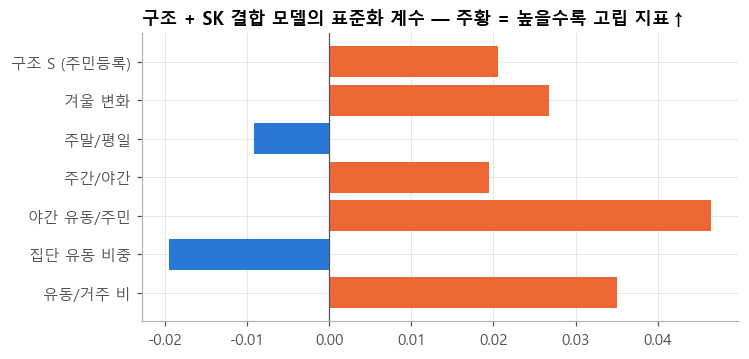

,mean,min,50%,max
지역,,,,
강원 춘천시,1.092,0.900,1.091,1.320
서울 강남구,1.067,0.826,1.084,1.365


In [6]:
G = U[U['지역'] == '서울 강남구'].merge(TS[['adm_cd', '성별', '연령5', 'y', 'y_rel', '총인구']].rename(columns={'adm_cd': 'SGIS코드'}),
                                    on=['SGIS코드', '성별', '연령5'], how='inner')
U['logS'] = np.log(U['S'].clip(lower=.2)); G['logS'] = np.log(G['S'].clip(lower=.2))
F_ALL = FA_P + ['logS']
print('강남 학습 행:', len(G), '| 동:', G['SGIS코드'].nunique())
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
def lodo(df, feats):                       # 동 하나씩 빼고 학습 → 빠진 동 예측
    p = pd.Series(0.0, index=df.index)
    for tr, te in LeaveOneGroupOut().split(df, groups=df['SGIS코드']):
        p.iloc[te] = ridge().fit(df.iloc[tr][feats], np.log(df.iloc[tr]['y_rel'])).predict(df.iloc[te][feats])
    return np.exp(p)
G['SA_cv'] = lodo(G, F_ALL); G['S_only_cv'] = lodo(G, ['logS']); G['A_only_cv'] = lodo(G, FA_P)
SA_MODEL = ridge().fit(G[F_ALL], np.log(G['y_rel']))
coefA = pd.Series(SA_MODEL[-1].coef_, index=F_A + ['구조 S (주민등록)'])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(coefA.index, coefA.values, color=['#eb6834' if v > 0 else '#2a78d6' for v in coefA.values]); ax.axvline(0, color=INK2, lw=.8)
ax.set_title('구조 + SK 결합 모델의 표준화 계수 — 주황 = 높을수록 고립 지표↑'); plt.show()
U['SA'] = np.exp(SA_MODEL.predict(U[F_ALL]))       # 구조 + SK 행동을 합친 상대 위험 (1 = 같은 성·연령 평균)
U.groupby('지역')['SA'].describe()[['mean', 'min', '50%', 'max']].round(3)

## 5. 집단 행동 C — 신한카드 (제공 데이터)

> **왜** 카드에만 있는 생활 소비 행동(외부활동·의료·심야·참여도)을 집단 단위로 반영합니다.  
> **결과** 정답으로 검증할 수 없는 축이라 영향 범위를 ±10% 안팎으로 작게 두고, 카드의 주 역할은 9장의 실시간 신호로 맡겼습니다.


In [7]:
%%time
REN = {'기준일자': '일자', '가맹점 위치정보(시·군·구)': '지역', '가맹점 업종': '업종', '이용고객 성별': '성별', '이용고객 연령대': '연령대',
       '결제금액 합계': '금액', '결제건수 합계': '건수'}
EXCL = ['ZZ_나머지', '세금공과금', '보험', '상품권/복권', '통신요금(이동,시내전화)', '통신요금(PC통신,무선호출)', '학교등록금', '결제대행(PG)']
OUTD_ = ['한식', '양식', '일식', '중식', '기타요식', '패스트푸드', '제과점', '커피전문점', '노래방', '영화/공연', '게임방/오락실', '종합레저타운/놀이동산',
         '스포츠시설', '헬스장', '실내/실외골프장', '싸우나/목욕탕', '유흥업소', '주류판매', '여행사/항공사', '호텔/콘도', '고속버스/철도/여객선', '택시']
MED = ['일반병원', '종합병원', '치과병원', '한의원', '기타의료', '약국', '보건소']
card = pd.read_csv(DATA / '신한카드_데이터1_시간대별.csv', dtype={'기준일자': str}).rename(columns=REN)
card = card[(card['성별'] != '법인') & ~card['업종'].isin(EXCL)].copy()
card['일자'] = pd.to_datetime(card['일자'])
card['연령5'] = card['연령대'].str.replace(' ', '').map(lambda a: None if a == '10대' else ('60대+' if a in ('60대', '70대', '80대', '90대') else a))
card = card.dropna(subset=['연령5'])
k = ['지역', '성별', '연령5']; base = card.groupby(k)['건수'].sum()
CI = pd.DataFrame({'외부활동%': card[card['업종'].isin(OUTD_)].groupby(k)['건수'].sum() / base * 100,
                   '의료%': card[card['업종'].isin(MED)].groupby(k)['건수'].sum() / base * 100,
                   '심야%': card[card['시간대'] == '00_05'].groupby(k)['건수'].sum() / base * 100})
pop_sh = skl.merge(CODES[['SGIS코드', '지역']], on='SGIS코드').groupby(k)['유동'].sum(); pop_sh = pop_sh / pop_sh.groupby('지역').transform('sum')
CI['참여도'] = (base / base.groupby('지역').transform('sum')) / pop_sh
# 같은 연령 안(성별 2 × 지역 2 = 4개 집단)에서의 상대 위치 → 연령 효과는 B가 이미 반영하므로 중복을 피함
Z = CI.groupby('연령5').transform(lambda s: (s - s.mean()) / (s.std() + 1e-9))
# 방향은 02 결과·문헌 기반, 크기는 정답으로 검증할 수 없어 보수적으로(±10% 안팎) 둠
W_C = {'외부활동%': -.04, '의료%': +.02, '참여도': -.04, '심야%': +.02}
CI['C'] = np.exp(sum(w * Z[f] for f, w in W_C.items()))
display(CI.round(3))
U = U.merge(CI[['C']].reset_index(), on=k, how='left')

외부활동%    의료%   심야%   참여도     C
지역     성별 연령5                                 
강원 춘천시 남성 20대  38.258  3.025 8.559 0.990 0.982
          30대  35.737  6.169 4.216 1.894 0.930
          40대  34.130  7.771 2.496 1.289 0.938
          50대  34.905  7.961 2.616 1.106 0.943
          60대+ 30.039 13.355 1.661 0.703 0.919
       여성 20대  41.129  5.420 4.380 1.057 0.930
          30대  38.211 10.370 1.547 1.256 0.982
          40대  35.675 10.092 1.209 0.924 1.022
          50대  34.290 10.751 1.286 0.931 1.014
          60대+ 26.636 15.862 0.626 0.507 1.040
서울 강남구 남성 20대  33.205  2.072 8.116 0.760 1.104
          30대  28.818  2.589 7.154 1.394 1.059
          40대  22.278  3.291 5.698 1.182 1.040
          50대  24.899  4.283 4.154 0.988 1.067
          60대+ 25.150  8.543 2.429 0.611 1.012
       여성 20대  37.445  4.090 3.413 0.908 0.993
          30대  32.714  5.299 3.142 1.116 1.035
          40대  24.662  4.716 3.288 1.203 1.003
          50대  25.382  5.078 2.658 1.137 0.980
          60대+ 21.728  8.760 1.628 0.608 1.034

CPU times: total: 6.98 s
Wall time: 7.31 s


## 6. 위험도 산출 · 5단계

> **왜** 세 축을 곱해 위험점수를 만들고, 공식 고립률(33%)에 맞춰 5단계로 나눕니다.  
> **결과** 지역 안 단계와 생애단계 안 단계 두 가지를 산출했습니다. 강남은 역삼1·논현2동 50~60대 남성, 춘천은 효자3·조운동 50~60대 남성이 1순위입니다.


① 지역 내 단계 — 지역별 거주 인구 분포(%) (정의상 각 지역 5/10/18/27/40%)


단계,심각,경계,주의,관심,정상
지역,,,,,
강원 춘천시,4.800,9.800,18.100,27.100,40.100
서울 강남구,4.500,10.400,17.800,26.500,40.800


① 지역 내 단계 — 지역 × 연령별 거주 인구 분포(%)


단계              심각     경계     주의     관심     정상
지역     연령5                                    
강원 춘천시 20대   0.000  0.000  0.000  2.200 97.800
       30대   0.000  0.000  0.000  3.300 96.700
       40대   0.000  0.000  0.900 20.900 78.200
       50대   3.600  7.500 24.900 64.000  0.000
       60대+ 11.300 22.900 36.100 29.800  0.000
서울 강남구 20대   0.000  0.000  0.000 18.400 81.600
       30대   0.000  0.000  0.000 29.900 70.100
       40대   0.000  0.000 12.500 31.900 55.600
       50대   9.400 14.600 33.000 28.200 14.800
       60대+  9.200 26.500 30.500 23.200 10.600

② 생애단계 내 단계 — 지역 × 연령별 거주 인구 분포(%)


생애단계 내 단계      심각     경계     주의     관심     정상
지역     연령5                                   
강원 춘천시 20대  3.900  6.200 18.700 29.300 41.900
       30대  3.300  8.500 15.100 29.700 43.400
       40대  4.500 10.400 17.400 24.900 42.700
       50대  3.800  9.600 19.100 24.600 42.900
       60대+ 4.400 10.100 17.800 26.500 41.200
서울 강남구 20대  3.800 10.300 18.000 26.000 41.800
       30대  4.600  8.900 19.000 26.000 41.500
       40대  4.300  8.200 18.600 25.100 43.800
       50대  4.500  9.600 18.100 24.800 43.000
       60대+ 3.700  9.300 19.400 27.000 40.600

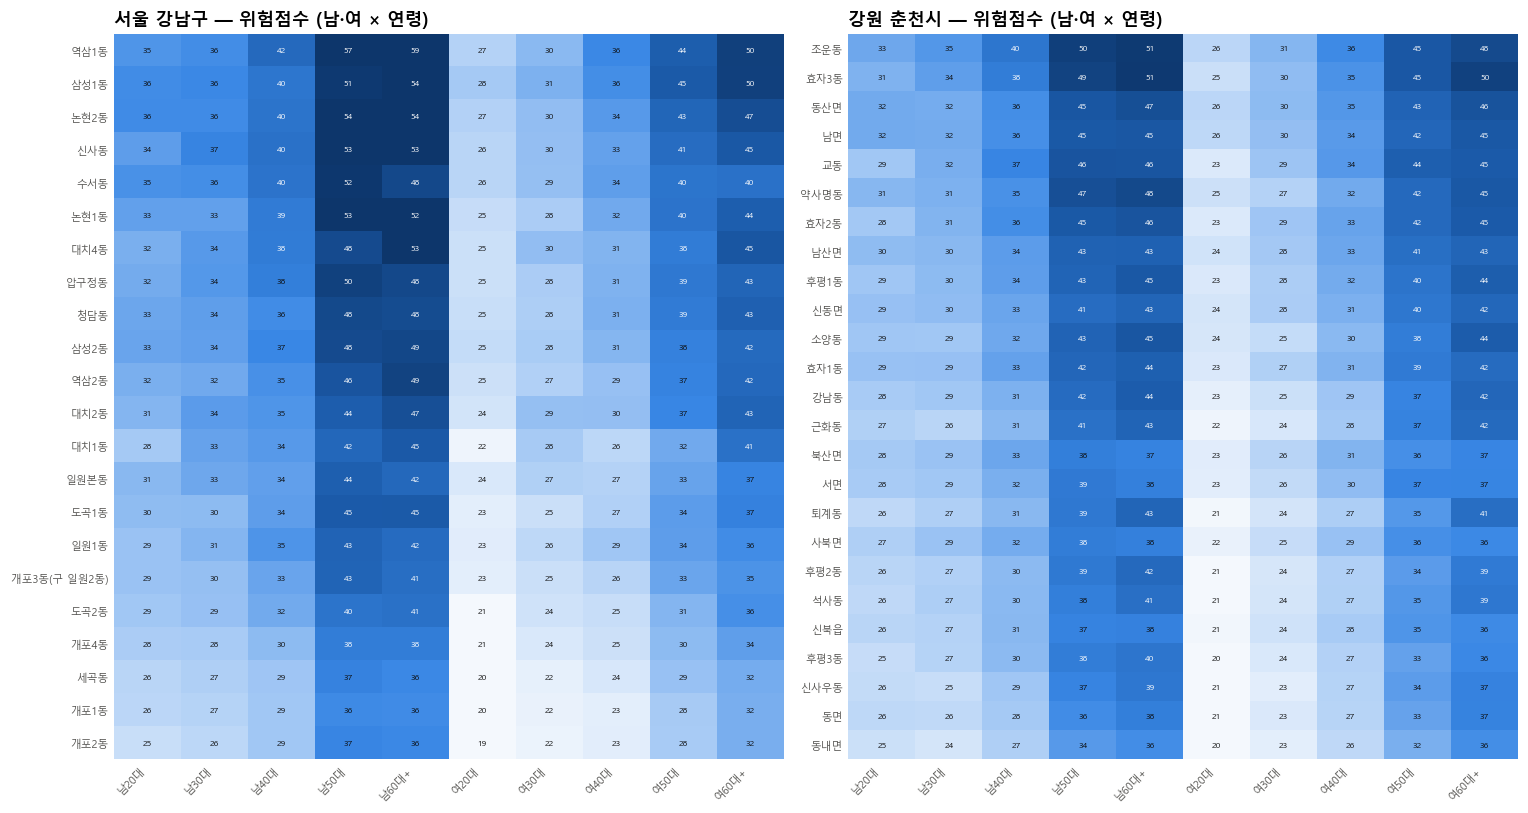

In [8]:
U['위험점수'] = U['B 기본 고립률(%)'] * U['SA'] * U['C']
# 5단계: 거주 인구 가중 누적 비중으로 구분 — '주의' 이상 = 공식 사회적 고립도 33.0%에 맞춤 (유병률 기준점)
CUTS = [('심각', .05), ('경계', .15), ('주의', .33), ('관심', .60), ('정상', 1.0)]
def levels(df, score='위험점수', w='주민'):
    d = df.sort_values(score, ascending=False); cum = d[w].fillna(0).cumsum() / d[w].fillna(0).sum()
    lab = pd.Series('정상', index=d.index)
    for name, cut in reversed(CUTS): lab[cum <= cut] = name
    return lab.reindex(df.index)
# ① 지역 내 단계: 대응은 구청·시청이 각자 관할에서 하고, SK 지표를 지역 안 순위로 썼으므로 지역끼리 한 줄로 세우지 않음
U['단계'] = pd.concat([levels(g) for _, g in U.groupby('지역')])
# ② 지역 × 생애단계 내 단계: 생애주기별 사업 대상 선정용 (경남 지침 p.7 '생애주기별로 사업대상을 선정' 권고)
U['생애단계 내 단계'] = pd.concat([levels(g) for _, g in U.groupby(['지역', '연령5'])])
ORDER = ['심각', '경계', '주의', '관심', '정상']
summ = U.groupby(['지역', '단계'])['주민'].sum().unstack().reindex(columns=ORDER).fillna(0)
summ = (summ.div(summ.sum(axis=1), axis=0) * 100).round(1)
print('① 지역 내 단계 — 지역별 거주 인구 분포(%) (정의상 각 지역 5/10/18/27/40%)'); display(summ)
lv = U.groupby(['지역', '연령5', '단계'])['주민'].sum().unstack().reindex(columns=ORDER).fillna(0)
print('① 지역 내 단계 — 지역 × 연령별 거주 인구 분포(%)'); display((lv.div(lv.sum(axis=1), axis=0) * 100).round(1))
lv2 = U.groupby(['지역', '연령5', '생애단계 내 단계'])['주민'].sum().unstack().reindex(columns=ORDER).fillna(0)
print('② 생애단계 내 단계 — 지역 × 연령별 거주 인구 분포(%)'); display((lv2.div(lv2.sum(axis=1), axis=0) * 100).round(1))
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, r in zip(axes, MAIN):
    p = U[U['지역'] == r].pivot_table(index='읍면동명', columns=['성별', '연령5'], values='위험점수')
    p = p.loc[p.mean(axis=1).sort_values(ascending=False).index]; p.columns = [f'{s[0]}{a}' for s, a in p.columns]
    heat(ax, p, fmt='{:.0f}', vmin=U['위험점수'].quantile(.02), vmax=U['위험점수'].quantile(.98), fs=7, rot=45); ax.set_title(f'{r} — 위험점수 (남·여 × 연령)')
plt.tight_layout(); plt.show()

In [9]:
cols = ['지역', '읍면동명', '성별', '연령5', '주민', '위험점수', '단계', '생애단계 내 단계', 'B 기본 고립률(%)', 'S', 'SA', 'C']
for r in MAIN:
    print(f'① [{r}] 지역 내 우선 지원 대상 상위 8'); display(U[U['지역'] == r].sort_values('위험점수', ascending=False)[cols].head(8).round(2))
print('② 지역 × 생애단계별 우선 지원 대상 1순위')
display(U.sort_values('위험점수', ascending=False).groupby(['지역', '연령5'], sort=False).head(1).sort_values(['지역', '연령5'])[cols].round(2))
for r in MAIN:
    print(f'[{r}] 단계별 집단 수:', U[U['지역'] == r]['단계'].value_counts().reindex(ORDER).fillna(0).astype(int).to_dict())

① [서울 강남구] 지역 내 우선 지원 대상 상위 8


,지역,읍면동명,성별,연령5,주민,위험점수,단계,생애단계 내 단계,B 기본 고립률(%),S,SA,C
74,서울 강남구,역삼1동,남성,60대+,2785,58.890,심각,심각,42.620,1.110,1.360,1.010
73,서울 강남구,역삼1동,남성,50대,2454,56.810,심각,심각,40.240,1.110,1.320,1.070
23,서울 강남구,논현2동,남성,50대,1547,54.010,심각,심각,40.240,1.220,1.260,1.070
24,서울 강남구,논현2동,남성,60대+,2049,53.720,심각,심각,42.620,1.220,1.240,1.010
34,서울 강남구,삼성1동,남성,60대+,1695,53.580,심각,경계,42.620,1.090,1.240,1.010
13,서울 강남구,논현1동,남성,50대,1397,53.090,심각,경계,40.240,1.230,1.240,1.070
4,서울 강남구,신사동,남성,60대+,1953,53.010,심각,경계,42.620,1.130,1.230,1.010
3,서울 강남구,신사동,남성,50대,1226,52.940,심각,경계,40.240,1.130,1.230,1.070


① [강원 춘천시] 지역 내 우선 지원 대상 상위 8


,지역,읍면동명,성별,연령5,주민,위험점수,단계,생애단계 내 단계,B 기본 고립률(%),S,SA,C
424,강원 춘천시,효자3동,남성,60대+,622,51.260,심각,심각,42.620,1.360,1.310,0.920
334,강원 춘천시,조운동,남성,60대+,461,51.140,심각,심각,42.620,1.630,1.310,0.920
333,강원 춘천시,조운동,남성,50대,222,50.120,심각,심각,40.240,1.630,1.320,0.940
429,강원 춘천시,효자3동,여성,60대+,774,49.600,심각,심각,36.420,1.360,1.310,1.040
423,강원 춘천시,효자3동,남성,50대,284,49.370,심각,심각,40.240,1.360,1.300,0.940
344,강원 춘천시,약사명동,남성,60대+,618,48.150,심각,심각,42.620,1.270,1.230,0.920
339,강원 춘천시,조운동,여성,60대+,619,47.950,심각,심각,36.420,1.630,1.270,1.040
244,강원 춘천시,동산면,남성,60대+,449,46.970,심각,심각,42.620,1.460,1.200,0.920


② 지역 × 생애단계별 우선 지원 대상 1순위


,지역,읍면동명,성별,연령5,주민,위험점수,단계,생애단계 내 단계,B 기본 고립률(%),S,SA,C
330,강원 춘천시,조운동,남성,20대,132,32.570,관심,심각,26.400,1.630,1.260,0.980
331,강원 춘천시,조운동,남성,30대,160,34.610,관심,심각,28.670,1.630,1.300,0.930
332,강원 춘천시,조운동,남성,40대,129,39.540,주의,심각,31.910,1.630,1.320,0.940
333,강원 춘천시,조운동,남성,50대,222,50.120,심각,심각,40.240,1.630,1.320,0.940
424,강원 춘천시,효자3동,남성,60대+,622,51.260,심각,심각,42.620,1.360,1.310,0.920
20,서울 강남구,논현2동,남성,20대,1138,36.030,관심,심각,26.400,1.220,1.240,1.100
1,서울 강남구,신사동,남성,30대,860,37.030,관심,심각,28.670,1.130,1.220,1.060
72,서울 강남구,역삼1동,남성,40대,3159,41.930,주의,심각,31.910,1.110,1.260,1.040
73,서울 강남구,역삼1동,남성,50대,2454,56.810,심각,심각,40.240,1.110,1.320,1.070
74,서울 강남구,역삼1동,남성,60대+,2785,58.890,심각,심각,42.620,1.110,1.360,1.010


[서울 강남구] 단계별 집단 수: {'심각': 12, '경계': 19, '주의': 37, '관심': 59, '정상': 93}
[강원 춘천시] 단계별 집단 수: {'심각': 20, '경계': 21, '주의': 27, '관심': 70, '정상': 112}


## 7. 성능 평가 — 제공 데이터를 빼면 얼마나 떨어지는가 (제거 실험)

> **왜** 제공 데이터가 성능에 실제로 기여하는지 빼 보면서 확인합니다.  
> **결과** 동 순위 ρ: 공식 통계만 0 → 외부 구조 0.28 → SK 포함 0.49로 올랐습니다. 향상도도 외부만 1.05, SK 포함 1.12~1.14입니다(이론상 최대 1.41).

- **동 순위 ρ**: 같은 성·연령 안에서 21개 동의 순위를 정답과 얼마나 같게 매기는가 (0 = 무작위, 1 = 완벽)
- **향상도**: 점수 상위 20% 동(4~5개)의 실제 고립 비율이 그 성·연령 평균의 몇 배인가 (1.0 = 무작위). 정답으로 고른 경우(이론상 최대)도 함께 표시

In [10]:
E = G.merge(U[['SGIS코드', '성별', '연령5', 'C']], on=['SGIS코드', '성별', '연령5'])
E['B'] = E['B 기본 고립률(%)']
VAR = [('B (공식 성·연령만)', E['B'], '외부'), ('B × S (외부 구조만)', E['B'] * E['S_only_cv'], '외부'),
       ('B × A (SK만)', E['B'] * E['A_only_cv'], '제공 (SK)'), ('B × S·A (외부 + SK)', E['B'] * E['SA_cv'], '외부 + 제공 (SK)'),
       ('B × S·A × C (최종)', E['B'] * E['SA_cv'] * E['C'], '외부 + 제공 (SK·신한)'), ('정답으로 고른 경우 (이론상 최대)', E['y'], '—')]
def lift(df, s, share=.2):
    out = []
    for _, g in df.assign(_s=s).groupby('cell'):
        n = max(1, int(round(len(g) * share)))
        out.append(1.0 if g['_s'].nunique() == 1 else g.nlargest(n, '_s')['y'].mean() / g['y'].mean())   # 점수가 모두 같으면 무작위(1.0)
    return np.mean(out)
rows = []
for name, s, src in VAR:
    wr = np.array([spearmanr(g['y'], g['_s'])[0] if g['_s'].nunique() > 1 else 0 for _, g in E.assign(_s=s).groupby('cell')])
    bs = [np.random.default_rng(i).choice(wr, len(wr)).mean() for i in range(1000)]
    rows.append({'모델': name, '사용 데이터': src, '동 순위 ρ': wr.mean(), '95% 구간': f'{np.percentile(bs, 2.5):.2f}~{np.percentile(bs, 97.5):.2f}',
                 '향상도 (상위 20% 동)': lift(E, s)})
ABL = pd.DataFrame(rows)
ABL.round(3)

,모델,사용 데이터,동 순위 ρ,95% 구간,향상도 (상위 20% 동)
0,B (공식 성·연령만),외부,0.000,0.00~0.00,1.000
1,B × S (외부 구조만),외부,0.281,0.08~0.48,1.055
2,B × A (SK만),제공 (SK),0.487,0.35~0.62,1.137
3,B × S·A (외부 + SK),외부 + 제공 (SK),0.485,0.33~0.63,1.119
4,B × S·A × C (최종),외부 + 제공 (SK·신한),0.485,0.33~0.63,1.119
5,정답으로 고른 경우 (이론상 최대),—,1.000,1.00~1.00,1.413


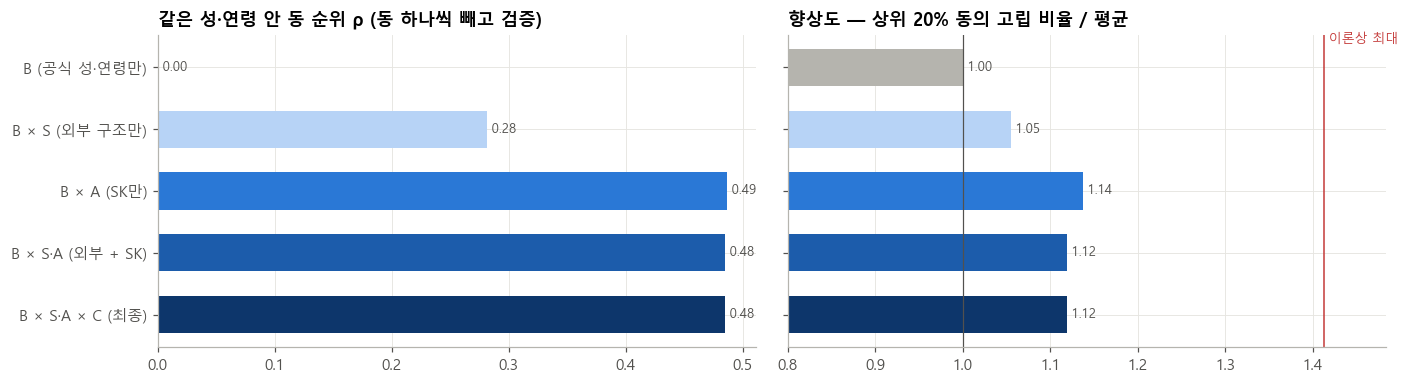

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
A_ = ABL.iloc[:-1][::-1]; colors = [GRAY, '#b7d3f6', '#2a78d6', '#1c5cab', '#0d366b'][::-1]
axes[0].barh(A_['모델'], A_['동 순위 ρ'], color=colors, height=.6); axes[0].set_title('같은 성·연령 안 동 순위 ρ (동 하나씩 빼고 검증)')
axes[1].barh(A_['모델'], A_['향상도 (상위 20% 동)'], color=colors, height=.6); axes[1].axvline(1, color=INK2, lw=.8)
axes[1].axvline(ABL.iloc[-1]['향상도 (상위 20% 동)'], color='#c43a39', lw=1); axes[1].set_xlim(.8, None)
axes[1].text(ABL.iloc[-1]['향상도 (상위 20% 동)'], 4.4, ' 이론상 최대', color='#c43a39', fontsize=8.5); axes[1].set_title('향상도 — 상위 20% 동의 고립 비율 / 평균')
for ax, col in zip(axes, ['동 순위 ρ', '향상도 (상위 20% 동)']):
    for y_, v in enumerate(A_[col]): ax.text(v, y_, f' {v:.2f}', va='center', fontsize=8.5, color=INK2)
plt.tight_layout(); plt.show()

## 8. 요인 기여도 — 왜 이 동·집단이 위험한가 (에이전트 '원인 분석'의 근거)

> **왜** 에이전트가 “왜 위험한가”를 설명하려면 요인별 기여를 나눠야 합니다.  
> **결과** 위험점수 차이의 49%를 제공 데이터가 설명합니다(SK 37%, 카드 12%). 상위 집단의 주 요인은 야간 유동·유동/거주 비입니다.


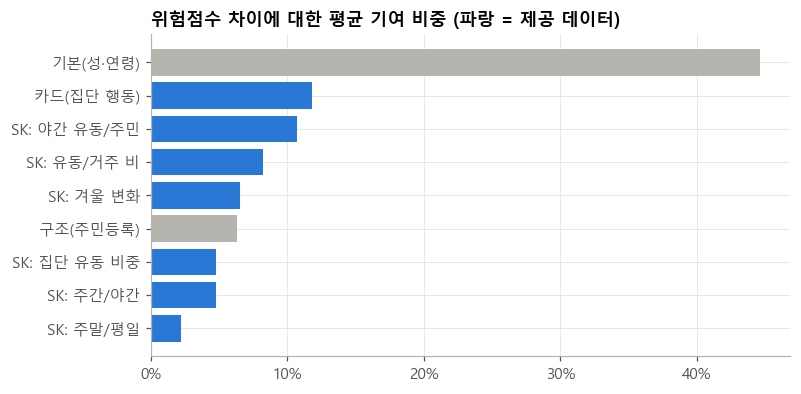

제공 데이터(SK·신한) 기여 합계: 49.1%  (SK 37.3%, 카드 11.8%)


,지역,읍면동명,성별,연령5,단계,주요 요인
74,서울 강남구,역삼1동,남성,60대+,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
73,서울 강남구,역삼1동,남성,50대,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, 카드(집단 행동) ↑"
23,서울 강남구,논현2동,남성,50대,심각,"기본(성·연령) ↑, 카드(집단 행동) ↑, SK: 야간 유동/주민 ↑"
24,서울 강남구,논현2동,남성,60대+,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
34,서울 강남구,삼성1동,남성,60대+,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
13,서울 강남구,논현1동,남성,50대,심각,"기본(성·연령) ↑, 카드(집단 행동) ↑, SK: 겨울 변화 ↑"
4,서울 강남구,신사동,남성,60대+,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
3,서울 강남구,신사동,남성,50대,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, 카드(집단 행동) ↑"
64,서울 강남구,대치4동,남성,60대+,심각,"기본(성·연령) ↑, SK: 유동/거주 비 ↑, 구조(주민등록) ↑"
14,서울 강남구,논현1동,남성,60대+,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 겨울 변화 ↑"


In [12]:
sc, mu, cf = SA_MODEL[0].scale_, SA_MODEL[0].mean_, SA_MODEL[-1].coef_
contrib = pd.DataFrame({('SK: ' + f if f != 'logS' else '구조(주민등록)'): cf[i] * (U[fp] - mu[i]) / sc[i]
                        for i, (f, fp) in enumerate(zip(F_A + ['logS'], F_ALL))})
contrib['기본(성·연령)'] = np.log(U['B 기본 고립률(%)'] / U['B 기본 고립률(%)'].mean())
contrib['카드(집단 행동)'] = np.log(U['C'])
U['logSK'] = contrib[[c for c in contrib if c.startswith('SK')]].sum(axis=1); U['logST'] = contrib['구조(주민등록)']
U['logB'] = np.log(U['B 기본 고립률(%)']); U['logC'] = np.log(U['C'])
U['주요 요인'] = [', '.join(f"{c} {'↑' if contrib.loc[i, c] > 0 else '↓'}" for c in contrib.loc[i].abs().sort_values(ascending=False).index[:3]) for i in U.index]
share = contrib.abs().div(contrib.abs().sum(axis=1), axis=0).mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(share.index[::-1], share.values[::-1], color=['#2a78d6' if s.startswith(('SK', '카드')) else GRAY for s in share.index[::-1]])
ax.set_title('위험점수 차이에 대한 평균 기여 비중 (파랑 = 제공 데이터)'); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); plt.show()
print(f"제공 데이터(SK·신한) 기여 합계: {share[[s for s in share.index if s.startswith(('SK', '카드'))]].sum():.1f}%  "
      f"(SK {share[[s for s in share.index if s.startswith('SK')]].sum():.1f}%, 카드 {share.get('카드(집단 행동)', 0):.1f}%)")
U.sort_values('위험점수', ascending=False)[['지역', '읍면동명', '성별', '연령5', '단계', '주요 요인']].head(10)

## 9. 시점 신호 T — 신한카드 일별 + 기상청 보정 → '지속 감소' 시 단계 상향

> **왜** 일시적 감소가 아니라 “지속된 감소”만 실시간으로 잡는 규칙을 만들고 성능을 시험합니다.  
> **결과** 6개월간 오경보 0건입니다. 3주간 지속 감소를 넣어 보면 −10%는 58%, −15%는 93%, −20% 이상은 100% 탐지하고 평균 8~12일 걸립니다.

- 대상: 지역 × 성 × 연령(20개 집단)의 **외부·사회활동형 소비** 일별 건수
- 기준선: 요일·공휴일·추석·월 + **날씨**(기상청 ASOS)로 예측한 '평소 값' → 실제와의 차이(잔차)
- **상향 규칙**: 잔차의 7일 이동평균이 −10% 이하로 **7일 이상 지속** → 해당 집단의 단계를 한 칸 올림 (일시적 감소는 무시)

,규칙,보정,6개월간 오경보 구간 수 (20개 집단 합)
0,"기본 (−10%, 7일 지속)",달력만 보정,0
1,"기본 (−10%, 7일 지속)",달력 + 날씨 보정,0
2,"민감 (−7%, 5일 지속)",달력만 보정,5
3,"민감 (−7%, 5일 지속)",달력 + 날씨 보정,3


기본 규칙(−10%, 7일)의 탐지 성능 — 3주간 지속 감소를 넣고, 평소 값은 그 구간을 뺀 데이터로 학습 (20개 집단 × 5회)


,탐지율,평균지연일
실제 감소폭,,
-10%,58.000,12.000
-15%,93.000,10.400
-20%,100.000,8.800
-30%,100.000,7.700


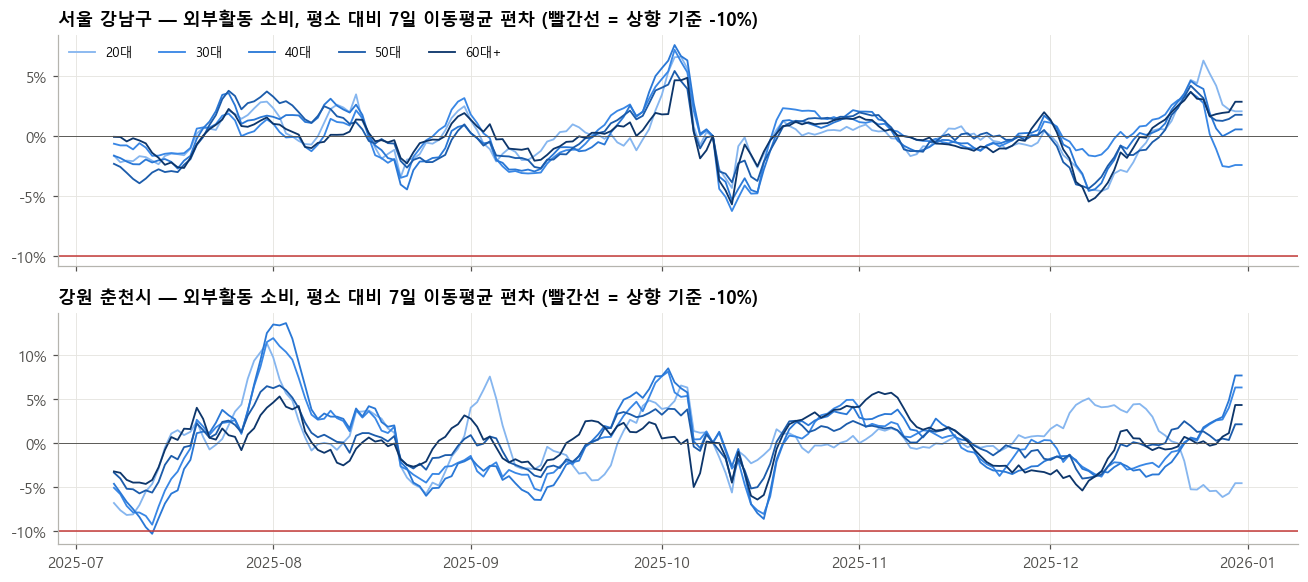

CPU times: total: 13.5 s
Wall time: 14.1 s


In [13]:
%%time
W = pd.read_csv(EXT / 'weather/kma_asos_daily_서울_춘천_202507_202512.csv', parse_dates=['일자'])[['지역', '일자', '평균기온', '최고기온', '일강수량']]
W['일강수량'] = W['일강수량'].fillna(0)
HOL = pd.to_datetime(['2025-08-15', '2025-10-03', '2025-10-06', '2025-10-07', '2025-10-08', '2025-10-09', '2025-12-25'])
CH = pd.date_range('2025-10-03', '2025-10-09')
def design(d, weather=True):
    X = pd.DataFrame({'const': 1.0}, index=d.index); dow = d['일자'].dt.dayofweek
    for kk in range(1, 7): X[f'd{kk}'] = (dow == kk) * 1.0
    X['hol'] = d['일자'].isin(HOL) * 1.0; X['ch'] = d['일자'].isin(CH) * 1.0
    X['x24'] = (d['일자'] == '2025-12-24') * 1.0; X['x31'] = (d['일자'] == '2025-12-31') * 1.0
    for kk in range(8, 13): X[f'm{kk}'] = (d['일자'].dt.month == kk) * 1.0
    if weather:
        p = d['일강수량']; X['r1'] = ((p > .5) & (p <= 10)) * 1.0; X['r2'] = ((p > 10) & (p <= 30)) * 1.0; X['r3'] = (p > 30) * 1.0
        X['td'] = d['평균기온'] - d.groupby(d['일자'].dt.month)['평균기온'].transform('mean'); X['heat'] = (d['최고기온'] >= 33) * 1.0
    return X
def resid(d, y, weather=True, train_mask=None):
    X = design(d, weather); m = np.ones(len(y), bool) if train_mask is None else train_mask
    b, *_ = np.linalg.lstsq(X.values[m], y[m], rcond=None); return pd.Series(y - X.values @ b, index=d['일자'])
def first_alarm(r, drop, days):
    roll = r.rolling(7).mean().values; n = 0
    for i, v in enumerate(roll):
        n = n + 1 if (not np.isnan(v) and v < np.log(1 + drop)) else 0
        if n >= days: return i
    return None
def count_episodes(r, drop, days):
    roll = r.rolling(7).mean().values; runs, n = 0, 0
    for v in list(roll) + [np.nan]:
        if not np.isnan(v) and v < np.log(1 + drop): n += 1
        else:
            runs += n >= days; n = 0
    return runs
RULES = {'기본 (−10%, 7일 지속)': (-.10, 7), '민감 (−7%, 5일 지속)': (-.07, 5)}
SER = {}
for (reg, sx, ag), g in card[card['업종'].isin(OUTD_)].groupby(['지역', '성별', '연령5']):
    SER[(reg, sx, ag)] = g.groupby('일자')['건수'].sum().rename('y').reset_index().merge(W[W['지역'] == reg], on='일자')
rows = []
for rname, (drop, days) in RULES.items():
    for wf, tag in [(False, '달력만 보정'), (True, '달력 + 날씨 보정')]:
        rows.append({'규칙': rname, '보정': tag, '6개월간 오경보 구간 수 (20개 집단 합)':
                     sum(count_episodes(resid(d, np.log(d['y'].values), wf), drop, days) for d in SER.values())})
FA_TAB = pd.DataFrame(rows); display(FA_TAB)

# 탐지 성능 시험: 실제로 3주간 활동이 줄었다고 가정하고 인위로 넣어 본 뒤, 규칙이 며칠 만에 잡는지 측정
rng = np.random.default_rng(0); sim = []
for D in [-.10, -.15, -.20, -.30]:
    for key, d in SER.items():
        for start in rng.integers(30, 150, 5):
            y = np.log(d['y'].values.copy()); y[start:start + 21] += np.log(1 + D)
            mask = np.ones(len(y), bool); mask[start:start + 28] = False        # 운영처럼: 감소 구간은 '평소 값' 학습에서 제외
            a = first_alarm(resid(d, y, True, mask), -.10, 7)
            hit = a is not None and start <= a < start + 21
            sim.append({'실제 감소폭': f'{int(D * 100)}%', '탐지': hit, '지연(일)': (a - start) if hit else np.nan})
SIM = pd.DataFrame(sim).groupby('실제 감소폭', sort=False).agg(탐지율=('탐지', 'mean'), 평균지연일=('지연(일)', 'mean'))
SIM['탐지율'] = (SIM['탐지율'] * 100).round(1)
print('기본 규칙(−10%, 7일)의 탐지 성능 — 3주간 지속 감소를 넣고, 평소 값은 그 구간을 뺀 데이터로 학습 (20개 집단 × 5회)'); display(SIM.round(1))
fig, axes = plt.subplots(2, 1, figsize=(12, 5.4), sharex=True)
for ax, reg in zip(axes, MAIN):
    for ag, col in zip(AGE5, ['#86b6ef', '#3987e5', '#2a78d6', '#1c5cab', '#0d366b']):
        s = sum(resid(SER[(reg, sx, ag)], np.log(SER[(reg, sx, ag)]['y'].values)).rolling(7).mean() for sx in SEX) / 2
        ax.plot(s.index, (np.exp(s.values) - 1) * 100, color=col, lw=1.2, label=ag)
    ax.axhline(-10, color='#c43a39', lw=1); ax.axhline(0, color=INK2, lw=.6)
    ax.set_title(f'{reg} — 외부활동 소비, 평소 대비 7일 이동평균 편차 (빨간선 = 상향 기준 -10%)'); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].legend(ncol=5, fontsize=8.5); plt.tight_layout(); plt.show()

## 10. 민감도 — 가중치를 바꿔도 우선순위가 유지되는가

> **왜** 가중치를 바꿔도 결과가 유지되는지 확인해야 결과를 믿을 수 있습니다.  
> **결과** 어떤 가중치를 0.5~2배로 바꿔도 순위 상관은 0.98 이상이고, 상위 15% 집단의 81~97%가 유지됩니다.


In [14]:
def score(wA=1., wS=1., wC=1.): return np.exp(U['logB'] + wA * U['logSK'] + wS * U['logST'] + wC * U['logC'])
base_rank = U['위험점수'].rank(ascending=False); base_top = set(U.nlargest(int(len(U) * .15), '위험점수').index)
rows = []
for nm, kw in [('SK 가중 ×0.5', dict(wA=.5)), ('SK 가중 ×1.5', dict(wA=1.5)), ('구조 가중 ×0.5', dict(wS=.5)), ('구조 가중 ×1.5', dict(wS=1.5)),
               ('카드 가중 ×0', dict(wC=0)), ('카드 가중 ×2', dict(wC=2))]:
    s = score(**kw); top = set(s.nlargest(int(len(U) * .15)).index)
    rows.append({'변경': nm, '전체 순위 상관 ρ': spearmanr(base_rank, s.rank(ascending=False))[0],
                 '상위 15% 집단 유지율(%)': len(top & base_top) / len(base_top) * 100,
                 '단계가 바뀐 집단(%)': (levels(U.assign(_s=s), '_s') != U['단계']).mean() * 100})
pd.DataFrame(rows).round(3)

,변경,전체 순위 상관 ρ,상위 15% 집단 유지율(%),단계가 바뀐 집단(%)
0,SK 가중 ×0.5,0.980,87.143,24.468
1,SK 가중 ×1.5,0.984,90.000,15.106
2,구조 가중 ×0.5,0.998,95.714,14.894
3,구조 가중 ×1.5,0.998,97.143,9.149
4,카드 가중 ×0,0.978,82.857,16.596
5,카드 가중 ×2,0.978,81.429,23.617


In [15]:
SAVE = ['지역', '읍면동명', 'SGIS코드', '행정기관코드', '유형', '성별', '연령5', '주민', 'B 기본 고립률(%)', 'S', 'SA', 'C', '위험점수', '단계', '생애단계 내 단계', '주요 요인'] + F_A
U[SAVE].sort_values('위험점수', ascending=False).to_csv(OUTD / '위험도_강남_춘천_동x성x연령.csv', index=False, encoding='utf-8-sig')
SIM.to_csv(OUTD / '시점신호_탐지성능.csv', encoding='utf-8-sig')
print('저장: outputs/위험도_강남_춘천_동x성x연령.csv, outputs/시점신호_탐지성능.csv')

저장: outputs/위험도_강남_춘천_동x성x연령.csv, outputs/시점신호_탐지성능.csv


## 11. 견고성 점검 — 설계 동결 · 시간 분할 검증 · 모델 비교 · 성별 분리 단계

> **왜** 04의 설계는 결과를 보며 고쳤기 때문에, 설계를 동결하고 학습에 쓰지 않은 미래 기간으로 다시 평가해야 합니다.  
> **결과** 가장 엄격한 검증(과거·다른 동으로 학습 → 미래의 처음 보는 동)에서도 ρ 0.46으로 유지돼, 낙관 편향은 작습니다.

04의 설계는 결과를 보면서 몇 차례 고쳤기 때문에, 같은 데이터로 평가하면 성능이 낙관적일 수 있습니다. 그래서 **설계를 고정(동결)한 뒤**, 학습에 쓰지 않은 **미래 기간**으로 다시 평가합니다.

In [16]:
CONFIG = {'동결일': '2026-10-13', '기본위험 B(연령별 %)': AGE_RATE, '성별 배수': SEX_MULT, '구조 지표 S': F_S, 'SK 행동 지표 A': F_A,
          '카드 가중치 C': W_C, '5단계 기준(누적 인구 비중)': CUTS, '실시간 규칙 T': {'7일 평균 감소': -0.10, '지속 일수': 7},
          '모델': 'StandardScaler + RidgeCV(alphas=logspace(-2,3,20))', '정답': GI + ' / 총인구, 같은 성·연령 서울 평균 대비'}
json.dump(CONFIG, open(OUTD / '모델설정_동결.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('설계 동결: outputs/모델설정_동결.json'); pd.Series({k: str(v)[:90] for k, v in CONFIG.items()}).to_frame('값')

설계 동결: outputs/모델설정_동결.json


,값
동결일,2026-10-13
기본위험 B(연령별 %),"{'20대': 24.4, '30대': 26.5, '40대': 29.5, '50대':..."
성별 배수,"{'남성': 1.081818181818182, '여성': 0.924242424242..."
구조 지표 S,"['1인세대비율', '65세+비율', '20~39세비율', '40~64세 남성비율'..."
SK 행동 지표 A,"['유동/거주 비', '집단 유동 비중', '야간 유동/주민', '주간/야간', '..."
카드 가중치 C,"{'외부활동%': -0.04, '의료%': 0.02, '참여도': -0.04, '심..."
5단계 기준(누적 인구 비중),"[('심각', 0.05), ('경계', 0.15), ('주의', 0.33), ('관..."
실시간 규칙 T,"{'7일 평균 감소': -0.1, '지속 일수': 7}"
모델,"StandardScaler + RidgeCV(alphas=logspace(-2,3,..."
정답,"외출-커뮤니케이션이 모두 적은 집단(전체) / 총인구, 같은 성·연령 서울 평균 대비"


### 11-1. 시간 분할 검증 — 7~9월로 학습하고 10~12월을 맞히는가

> **왜** 같은 기간으로 평가하면 “이미 본 데이터”를 맞히는 셈이라 성능이 부풀 수 있습니다.  
> **결과** 7~9월로 학습해 10~12월을 예측해도 ρ 0.46~0.49입니다. 다만 정답 자체의 시간 안정성(0.74)에는 못 미칩니다.

- SK 지표와 정답을 기간별로 다시 만듭니다. '겨울 변화'는 3개월 안에서 정의할 수 없어 **기간 내 변화(마지막 달 ÷ 첫 달)**로 바꿉니다.
- (a) 같은 기간 안에서 동 하나씩 빼고 검증 → (b) 과거로 학습해 미래를 예측(같은 동) → (c) **과거 + 다른 동으로 학습해 미래의 처음 보는 동을 예측**(가장 엄격)
- 비교 기준: '지난 기간 정답을 그대로 다음 기간 예측으로 쓰기'(정답 자체의 시간 안정성)

In [17]:
%%time
P1, P2 = ['202507', '202508', '202509'], ['202510', '202511', '202512']
K3 = ['SGIS코드', '성별', '연령5']
def period_target(months):
    s_ = si[si['기준년월'].isin(months)].groupby(['행정동코드', '자치구', '성별', '연령5'])[['총인구', GI]].sum().reset_index()
    s_['y'] = s_[GI] / s_['총인구'] * 100
    s_['y_rel'] = s_['y'] / s_.groupby(['성별', '연령5'])['y'].transform('mean')
    s_ = s_[s_['자치구'] == '강남구'].copy(); s_['SGIS코드'] = s_['행정동코드'].astype(str) + '0'
    return s_[s_['SGIS코드'] != '11230740'][K3 + ['y', 'y_rel']]
def period_features(months):
    sk = skl[skl['기준년월'].isin(months)]
    g = sk.groupby(K3)['유동'].mean().rename('집단유동').reset_index().merge(U[K3 + ['지역', '주민', 'logS', 'cell']], on=K3)
    df_ = sk.groupby('SGIS코드')['유동'].sum() / len(months)
    t_ = tm[tm['기준년월'].isin(months)].groupby('SGIS코드')[TM].sum(); w_ = wk[wk['기준년월'].isin(months)].groupby('SGIS코드')[WD].sum()
    dres = U.groupby('SGIS코드')['주민'].sum()
    g['유동/거주 비'] = np.log((g['집단유동'] + 1) / (g['주민'] + 1))
    g['집단 유동 비중'] = g['집단유동'] / g['SGIS코드'].map(df_)
    g['야간 유동/주민'] = g['SGIS코드'].map(np.log((t_[TM[:6]].sum(axis=1) / 6 / len(months) + 1) / (dres + 1)))
    g['주간/야간'] = g['SGIS코드'].map((t_[TM[9:18]].sum(axis=1) / 9) / (t_[TM[:6]].sum(axis=1) / 6))
    g['주말/평일'] = g['SGIS코드'].map(w_[WD[5:]].mean(axis=1) / w_[WD[:5]].mean(axis=1))
    se = sk.groupby(K3 + ['기준년월'])['유동'].sum().unstack()
    g['겨울 변화'] = g.set_index(K3).index.map(se[months[-1]] / se[months[0]] - 1)     # 기간 내 변화
    for f in F_A: g[f + '_p'] = g.groupby(['지역', '성별', '연령5'])[f].rank(pct=True)
    return g
D1 = period_features(P1).merge(period_target(P1), on=K3); D2 = period_features(P2).merge(period_target(P2), on=K3)
D2 = D2.set_index(K3).loc[D1.set_index(K3).index].reset_index()         # 같은 순서로 정렬
print('기간별 학습 행:', len(D1), len(D2))
def rho_cells(df, pred):
    wr = np.array([spearmanr(g['y_rel'], g['_p'])[0] for _, g in df.assign(_p=pred).groupby('cell')])
    bs = [np.random.default_rng(i).choice(wr, len(wr)).mean() for i in range(1000)]
    return wr.mean(), f'{np.percentile(bs, 2.5):.2f}~{np.percentile(bs, 97.5):.2f}'
rows = []
p = np.zeros(len(D1))
for tr, te in LeaveOneGroupOut().split(D1, groups=D1['SGIS코드']):
    p[te] = ridge().fit(D1.iloc[tr][F_ALL], np.log(D1.iloc[tr]['y_rel'])).predict(D1.iloc[te][F_ALL])
rows.append(('(a) 7~9월 안에서, 동 하나씩 빼고', *rho_cells(D1, p)))
m = ridge().fit(D1[F_ALL], np.log(D1['y_rel']))
rows.append(('(b) 7~9월로 학습 → 10~12월 예측 (같은 동)', *rho_cells(D2, m.predict(D2[F_ALL]))))
p = np.zeros(len(D2))
for tr, te in LeaveOneGroupOut().split(D1, groups=D1['SGIS코드']):
    p[te] = ridge().fit(D1.iloc[tr][F_ALL], np.log(D1.iloc[tr]['y_rel'])).predict(D2.iloc[te][F_ALL])
rows.append(('(c) 7~9월·다른 동으로 학습 → 10~12월의 처음 보는 동 (가장 엄격)', *rho_cells(D2, p)))
rows.append(('참고: 7~9월 정답을 10~12월 예측으로 그대로 사용', *rho_cells(D2, D1['y_rel'].values)))
TSPLIT = pd.DataFrame(rows, columns=['검증 방식', '동 순위 ρ', '95% 구간'])
TSPLIT.round(3)

기간별 학습 행: 210 210


CPU times: total: 2.73 s
Wall time: 3.03 s


,검증 방식,동 순위 ρ,95% 구간
0,"(a) 7~9월 안에서, 동 하나씩 빼고",0.473,0.33~0.61
1,(b) 7~9월로 학습 → 10~12월 예측 (같은 동),0.492,0.35~0.61
2,(c) 7~9월·다른 동으로 학습 → 10~12월의 처음 보는 동 (가장 엄격),0.458,0.30~0.59
3,참고: 7~9월 정답을 10~12월 예측으로 그대로 사용,0.736,0.63~0.82


### 11-2. 모델 비교 — 왜 릿지 회귀인가 (6개월 데이터, 동 하나씩 빼고 검증)

> **왜** “왜 이 모델인가”에 답하려면 같은 조건에서 다른 모델과 비교해야 합니다.  
> **결과** 선형 계열(릿지 0.46·라쏘 0.51)이 트리 계열(랜덤포레스트 0.38·LightGBM 0.31)보다 엄격한 검증에서 낫습니다. 동 21개라 복잡한 모델은 과적합됩니다.


In [18]:
%%time
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb, time
MODELS = {'선형회귀 (규제 없음)': lambda: make_pipeline(StandardScaler(), LinearRegression()),
          '릿지 회귀 (채택)': ridge,
          '라쏘 회귀': lambda: make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)),
          '랜덤포레스트': lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1),
          'LightGBM': lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=.03, num_leaves=7, min_child_samples=15, subsample=.8,
                                               subsample_freq=1, colsample_bytree=.8, verbose=-1, random_state=0)}
rows = []
for name, mk in MODELS.items():
    t0 = time.time(); p = np.zeros(len(G)); pt = np.zeros(len(D2))
    for tr, te in LeaveOneGroupOut().split(G, groups=G['SGIS코드']):
        p[te] = mk().fit(G.iloc[tr][F_ALL], np.log(G.iloc[tr]['y_rel'])).predict(G.iloc[te][F_ALL])
    for tr, te in LeaveOneGroupOut().split(D1, groups=D1['SGIS코드']):
        pt[te] = mk().fit(D1.iloc[tr][F_ALL], np.log(D1.iloc[tr]['y_rel'])).predict(D2.iloc[te][F_ALL])
    r1, c1 = rho_cells(G, p); r2, c2 = rho_cells(D2, pt)
    rows.append({'모델': name, '동 순위 ρ (6개월, 동 분할)': r1, '95% 구간': c1, '동 순위 ρ (시간+동 분할)': r2, '95% 구간 ': c2,
                 '요인별 설명 가능': '예' if name in ('선형회귀 (규제 없음)', '릿지 회귀 (채택)', '라쏘 회귀') else '제한적', '소요(초)': round(time.time() - t0, 1)})
MCOMP = pd.DataFrame(rows); MCOMP.round(3)

CPU times: total: 1min 15s
Wall time: 1min 6s


,모델,"동 순위 ρ (6개월, 동 분할)",95% 구간,동 순위 ρ (시간+동 분할),95% 구간,요인별 설명 가능,소요(초)
0,선형회귀 (규제 없음),0.443,0.28~0.60,0.448,0.27~0.61,예,1.100
1,릿지 회귀 (채택),0.485,0.33~0.63,0.458,0.30~0.59,예,1.100
2,라쏘 회귀,0.500,0.37~0.62,0.512,0.41~0.61,예,9.700
3,랜덤포레스트,0.483,0.38~0.58,0.384,0.30~0.47,제한적,46.200
4,LightGBM,0.394,0.29~0.49,0.309,0.26~0.37,제한적,7.500


### 11-3. 성별 분리 단계 — 여성 고립을 놓치지 않도록

> **왜** 상위 집단이 남성에 쏠려 여성 고립을 놓칠 수 있습니다.  
> **결과** 성별 안에서 단계를 매기면 '심각·경계' 중 여성 집단 비율이 강남 19% → 45%, 춘천 37% → 48%로 올라갑니다.


In [19]:
U['성별 내 단계'] = pd.concat([levels(g) for _, g in U.groupby(['지역', '성별'])])
hi = ['심각', '경계']
comp = pd.DataFrame({'지역 내 단계': U[U['단계'].isin(hi)].groupby('지역')['성별'].apply(lambda s: (s == '여성').mean() * 100),
                     '성별 내 단계': U[U['성별 내 단계'].isin(hi)].groupby('지역')['성별'].apply(lambda s: (s == '여성').mean() * 100)})
print("'심각·경계' 집단 중 여성 집단 비율(%)"); display(comp.round(1))
for r in MAIN:
    print(f'[{r}] 여성 우선 지원 대상 상위 5 (성별 내 단계)')
    display(U[(U['지역'] == r) & (U['성별'] == '여성')].sort_values('위험점수', ascending=False)[['읍면동명', '연령5', '주민', '위험점수', '단계', '성별 내 단계', '주요 요인']].head(5).round(2))
SAVE2 = SAVE + ['성별 내 단계']
U[SAVE2].sort_values('위험점수', ascending=False).to_csv(OUTD / '위험도_강남_춘천_동x성x연령.csv', index=False, encoding='utf-8-sig')
print('저장 갱신: outputs/위험도_강남_춘천_동x성x연령.csv (성별 내 단계 추가)')

'심각·경계' 집단 중 여성 집단 비율(%)


,지역 내 단계,성별 내 단계
지역,,
강원 춘천시,36.600,47.600
서울 강남구,19.400,44.800


[서울 강남구] 여성 우선 지원 대상 상위 5 (성별 내 단계)


,읍면동명,연령5,주민,위험점수,단계,성별 내 단계,주요 요인
79,역삼1동,60대+,3013,50.040,경계,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
39,삼성1동,60대+,1944,49.860,경계,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
29,논현2동,60대+,2551,47.140,경계,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
69,대치4동,60대+,1825,45.330,경계,심각,"기본(성·연령) ↑, SK: 유동/거주 비 ↑, 구조(주민등록) ↑"
9,신사동,60대+,2285,45.050,경계,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"


[강원 춘천시] 여성 우선 지원 대상 상위 5 (성별 내 단계)


,읍면동명,연령5,주민,위험점수,단계,성별 내 단계,주요 요인
429,효자3동,60대+,774,49.600,심각,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
339,조운동,60대+,619,47.950,심각,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, 구조(주민등록) ↑"
249,동산면,60대+,401,46.090,심각,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
428,효자3동,50대,226,45.170,심각,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, SK: 유동/거주 비 ↑"
338,조운동,50대,169,45.140,심각,심각,"기본(성·연령) ↑, SK: 야간 유동/주민 ↑, 구조(주민등록) ↑"


저장 갱신: outputs/위험도_강남_춘천_동x성x연령.csv (성별 내 단계 추가)


## 12. 요약 · 다음 단계

> **왜** 결과를 쉽게 정리하고 다음 단계로 넘깁니다.  
> **결과** 위험도 결과 파일(outputs/)과 한계·다음 단계를 정리했습니다.


### 한 줄 요약
**공식 고립률(기준) × 주민 구조 + SK 행동(어디서) × 카드 행동(누가)**으로 강남·춘천 470개 동·성·연령 집단의 위험도를 만들었습니다. SK가 들어가야 정답 순위를 맞히기 시작하고(ρ 0 → 0.49), 카드는 '평소보다 활동이 계속 줄었는가'를 매일 감시하는 실시간 신호를 맡습니다.

### 쉽게 풀어 보면
1. **기준점(B)**: 통계청 사회적 고립도를 출발점으로 둡니다. '50~60대 남성은 원래 고립되기 쉽다' 같은 사실입니다. 이 차이는 정답 데이터로는 검증할 수 없어서(정답이 연령대별 상위 2%로 정의됨) 공식 통계를 그대로 씁니다.
2. **동네 구조(S)**: 주민등록으로 '1인 세대가 많은 동네인가'를 봅니다. 서울 417개 동으로 학습했지만 설명력은 약했습니다(ρ 0.19). 그래서 보조 역할만 맡깁니다.
3. **SK 행동(A) — 핵심**: '그 집단이 동네에 얼마나 머무는가', '밤에 머무는 사람이 주민 대비 많은가', '겨울에도 줄지 않고 머무는가' 같은 행동 패턴입니다. 강남 정답으로 학습하니, 이 패턴이 강한 동·집단일수록 '외출·소통이 모두 적은 사람' 비율이 높았습니다.
4. **카드 행동(C)**: 같은 연령끼리 비교해 외부활동 소비가 적고 의료 소비가 많은 집단은 위험을 조금 올립니다. 정답으로 검증할 수 없어 영향은 ±10% 안팎으로 작게 뒀습니다.
5. **5단계**: 위험점수 순으로 줄을 세워 인구의 5%를 심각, 10%를 경계, 18%를 주의로 둡니다. 주의 이상이 33%로, 공식 고립률과 같습니다. 단계는 두 가지입니다.
   - **지역 내 단계**: 구청·시청의 전체 자원 배분용. 기본 위험이 높은 50~60대가 주로 올라옵니다.
   - **생애단계 내 단계**: 청년·중년·노년 사업별 대상 선정용. 같은 연령끼리 비교하므로 청년 위험 집단도 드러납니다.
6. **실시간 조정(T)**: 카드 일별 외부활동 소비를 '평소 값'(요일·공휴일·날씨로 예측)과 비교합니다. 7일 평균이 −10% 이하로 7일 이상 계속되면 그 집단의 단계를 한 칸 올립니다.

### 결과
| 항목 | 값 | 의미 |
|---|---|---|
| 동 순위 ρ (같은 성·연령 안, 강남 21개 동) | 공식 통계만 0 → 외부 구조 0.28 → **SK 포함 0.49** | 제공 데이터(SK)가 있어야 동 간 차이를 맞힙니다 |
| 향상도 (점수 상위 20% 동의 고립 비율 ÷ 평균) | 외부만 1.05 → **SK 포함 1.12~1.14** (이론상 최대 1.41) | 상위 동을 고르면 평균보다 12~14% 더 고립된 곳을 고릅니다 |
| 위험점수 차이에 대한 기여 | **제공 데이터 49%** (SK 37%, 카드 12%) | 결과의 절반을 제공 데이터가 결정합니다 |
| 실시간 규칙 오경보 | 6개월간 **0건** (날씨 보정 시 민감 규칙도 5 → 3건) | 비·명절 때문에 잘못 울리지 않습니다 |
| 실시간 규칙 탐지율 (3주 지속 감소) | −10%: 58% · −15%: 93% · −20% 이상: 100%, 평균 8~12일 | 집단 활동이 15% 이상 계속 줄면 거의 확실히 잡습니다 |
| 가중치 0.5~2배 변경 시 | 순위 상관 ≥ 0.98, 상위 15% 유지 81~97% | 가중치 선택에 크게 흔들리지 않습니다 |
| 1순위 (지역 내) | 강남: 역삼1·논현2동 50~60대 남성 / 춘천: 효자3·조운동 50~60대 남성 | 고독사 실태(50·60대 남성 54%)와 방향이 일치합니다 |
| 1순위 (생애단계 내, 청년) | 강남 20대: 논현2동 남성, 30대: 신사동 남성 / 춘천 20~40대: 조운동 남성 | 청년·중년 사업의 대상 후보입니다 |

### 견고성 점검 (11장)
| 점검 | 결과 | 의미 |
|---|---|---|
| 설계 동결 | `outputs/모델설정_동결.json` | 이후 평가는 이 설정 그대로 합니다 |
| 시간 분할 검증 (7~9월 학습 → 10~12월) | 같은 동 0.49 · **처음 보는 동 0.46** (같은 기간 0.47) | 결과를 보고 고친 데서 오는 낙관 편향은 작습니다 |
| 정답 자체의 시간 안정성 | 0.74 (지난 기간 정답으로 다음 기간 예측) | 모델이 잡지 못하는 동별 고유 요인이 아직 큽니다 |
| 모델 비교 (엄격한 검증) | 라쏘 0.51 · 릿지 0.46 · 선형 0.45 · 랜덤포레스트 0.38 · LightGBM 0.31 | 선형 계열이 낫습니다. 라쏘가 약간 높지만 신뢰구간이 겹쳐, 동결한 릿지를 유지합니다 |
| 성별 분리 단계 | '심각·경계' 중 여성 집단: 강남 19% → 45%, 춘천 37% → 48% | 여성 우선 대상(예: 역삼1·삼성1동 60대+ 여성, 효자3·조운동 60대+ 여성)이 드러납니다 |

### 한계 (보고서에 그대로 쓸 문장)
- 성능은 **강남 21개 동** 기준이고, 정답은 SKT 기반 추정치입니다. 입력(SK)과 정답의 출처가 같아 성능이 부풀 수 있습니다. '고립 예측'이 아니라 '통신 기반 고립 지표의 동 단위 재현'입니다. → 독립 지표 검증으로 전환 검토 중
- 춘천은 정답이 없어 강남에서 학습한 관계를 지역 안 순위로 옮겨 적용했습니다. 도농 차이가 있어 **현장 확인을 전제로 한 우선순위**로만 씁니다.
- 상위 집단이 대부분 남성인 이유는 공식 통계의 성별 차이(B)와 카드 지표(C) 때문입니다. 여성 고립을 놓치지 않도록 **생애단계 내 단계는 성별로도 따로 볼 것**을 권합니다.
- 카드 C의 가중치는 정답으로 검증하지 못했습니다(문헌 방향 + 보수적 크기). 판단도구 현장 조사 결과가 쌓이면 다시 학습해야 합니다.
- 실시간 규칙은 **집단 단위**라 개인의 고립은 잡지 못합니다. 대신 한파·재난처럼 집단 전체가 위축되는 상황을 잡는 데 적합합니다.

### 다음 단계 (05)
위험 단계 × 생애단계 × 주요 요인을 **복지서비스·시설**과 연결하는 매핑표를 만듭니다. 예를 들어 '야간 유동↑ 50대 남성 → 중장년 1인가구 사회관계망 프로그램'입니다.